# g-factor modulation by electric field — 2H-Ge nanowire quantum dot

Reads the data files written by `gfactor_xx_vs_E.py`, `gfactor_yy_vs_E.py`, `gfactor_zz_vs_E.py`:

`g{xx,yy,zz}_vs_E{y,z}_N{N}_L{L}.dat` with columns
`E(V/um)  g (signed)  dg(%)  |g|  overlap_min  E_pair(eV)  gap_next(eV)`

* **Figure 1** — (a) $g_{xx}$, (b) $g_{yy}$, (c) $g_{zz}$ vs $\mathcal{E}$
* **Figure 2** — (a)–(c) percentage change $\Delta g_{ii}/|g_{ii}(0)|$ vs $\mathcal{E}$

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

# ---------------- settings ----------------
DATA_DIR = "."          # folder with the .dat files
N, L = 100, 300          # must match the file names
OUT_PREFIX = f"gfactor_modulation_N{N}_L{L}"

COMPONENTS = ["xx", "yy", "zz"]
FIELDS = {
    "y": dict(label=r"$\mathcal{E}_y$", color="red",  marker="o"),
    "z": dict(label=r"$\mathcal{E}_z$", color="blue", marker="s"),
}
PANEL_LABELS = ["(a)", "(b)", "(c)"]

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["DejaVu Serif"],
    "mathtext.fontset": "dejavuserif",
    "font.size": 22,
    "axes.labelsize": 24,
    "axes.titlesize": 24,
    "xtick.labelsize": 22,
    "ytick.labelsize": 22,
    "legend.fontsize": 22,
    "axes.linewidth": 1.0,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.top": True, "ytick.right": True,
    "xtick.minor.visible": False, "ytick.minor.visible": False,
    "xtick.major.size": 6, "ytick.major.size": 6,
    "xtick.major.width": 1.0, "ytick.major.width": 1.0,
    "legend.frameon": False,
    "lines.linewidth": 1.8, "lines.markersize": 6,
})

In [2]:
COLS = ["E", "g", "dg", "gabs", "overlap", "E_pair", "gap_next"]

def load(comp, field):
    fname = os.path.join(DATA_DIR, f"g{comp}_vs_E{field}_N{N}_L{L}.dat")
    if not os.path.exists(fname):
        print(f"missing: {fname}")
        return None
    arr = np.loadtxt(fname, ndmin=2)
    return {c: arr[:, i] for i, c in enumerate(COLS)}

data = {(c, f): load(c, f) for c in COMPONENTS for f in FIELDS}

# quick sanity summary
for (c, f), d in data.items():
    if d is None:
        continue
    flips = np.where(np.diff(np.sign(d["g"])) != 0)[0]
    cross = ", ".join(f"{d['E'][i]:.2f}-{d['E'][i+1]:.2f}" for i in flips) or "none"
    print(f"g_{c} vs E_{f}: g(0)={d['g'][0]: .4f}  g(Emax)={d['g'][-1]: .4f}  "
          f"change={d['dg'][-1]: .1f}%  sign change (V/um): {cross}  "
          f"min overlap={d['overlap'][1:].min():.3f}")

g_xx vs E_y: g(0)= 0.2863  g(Emax)= 1.2270  change= 328.6%  sign change (V/um): none  min overlap=0.990
g_xx vs E_z: g(0)= 0.2863  g(Emax)= 0.0453  change=-84.2%  sign change (V/um): none  min overlap=0.797
g_yy vs E_y: g(0)= 0.4399  g(Emax)= 3.6964  change= 740.4%  sign change (V/um): none  min overlap=0.990
g_yy vs E_z: g(0)= 0.4399  g(Emax)=-0.4061  change=-192.3%  sign change (V/um): 1.40-1.75  min overlap=0.797
g_zz vs E_y: g(0)= 15.7683  g(Emax)= 12.4974  change=-20.7%  sign change (V/um): none  min overlap=0.990
g_zz vs E_z: g(0)= 15.7683  g(Emax)= 10.7702  change=-31.7%  sign change (V/um): none  min overlap=0.797


In [3]:
def plot_set(key, ylabel_fmt, fname, zero_line=False):
    fig, axs = plt.subplots(1, 3, figsize=(18, 5.4))
    for ax, comp, plab in zip(axs, COMPONENTS, PANEL_LABELS):
        for f, st in FIELDS.items():
            d = data[(comp, f)]
            if d is None:
                continue
            ax.plot(d["E"], d[key], marker=st["marker"], color=st["color"],
                    markerfacecolor="none", markeredgecolor=st["color"],
                    markeredgewidth=1.6, label=st["label"])
        if zero_line:
            ax.axhline(0, color="k", lw=0.8, ls="--")
        ax.set_xlabel(r"$\mathcal{E}$ (V/$\mu$m)", fontsize=24)
        ax.set_ylabel(ylabel_fmt.format(c=comp), fontsize=24)
        ax.tick_params(axis="both", labelsize=22)
        ax.minorticks_off()
        if plab == "(c)":
            lo, hi = ax.get_ylim()
            ax.set_ylim(lo, hi + 0.35 * (hi - lo))
        ax.text(0.04, 0.95, plab, transform=ax.transAxes, fontsize=24,
                ha="left", va="top")
        ax.legend(loc="best", fontsize=22)
    fig.tight_layout()
    fig.savefig(fname + ".pdf", bbox_inches="tight")
    fig.savefig(fname + ".svg", dpi=300, bbox_inches="tight")
    plt.show()
    print("saved", fname + ".pdf / .svg")

## Figure 1 — g-factor modulation

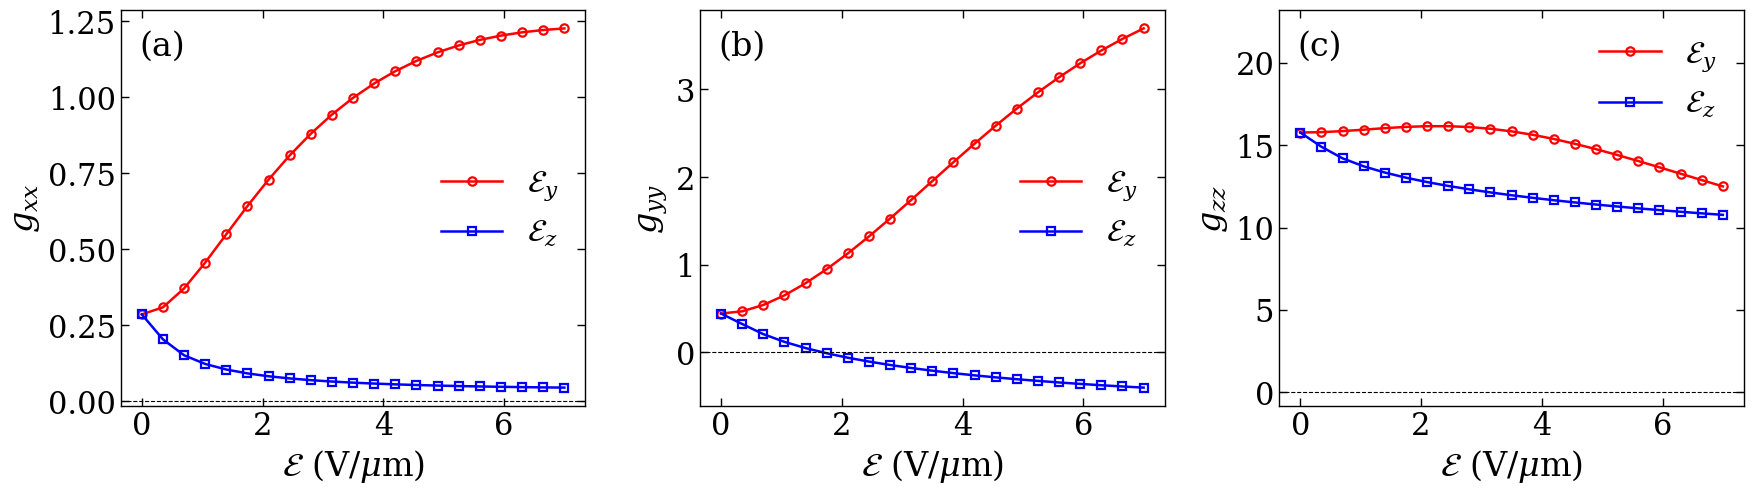

saved gfactor_modulation_N100_L300_g.pdf / .svg


In [4]:
plot_set("g", r"$g_{{{c}}}$", OUT_PREFIX + "_g", zero_line=True)

## Figure 2 — percentage change, $\Delta g_{ii}/|g_{ii}(0)| \times 100$

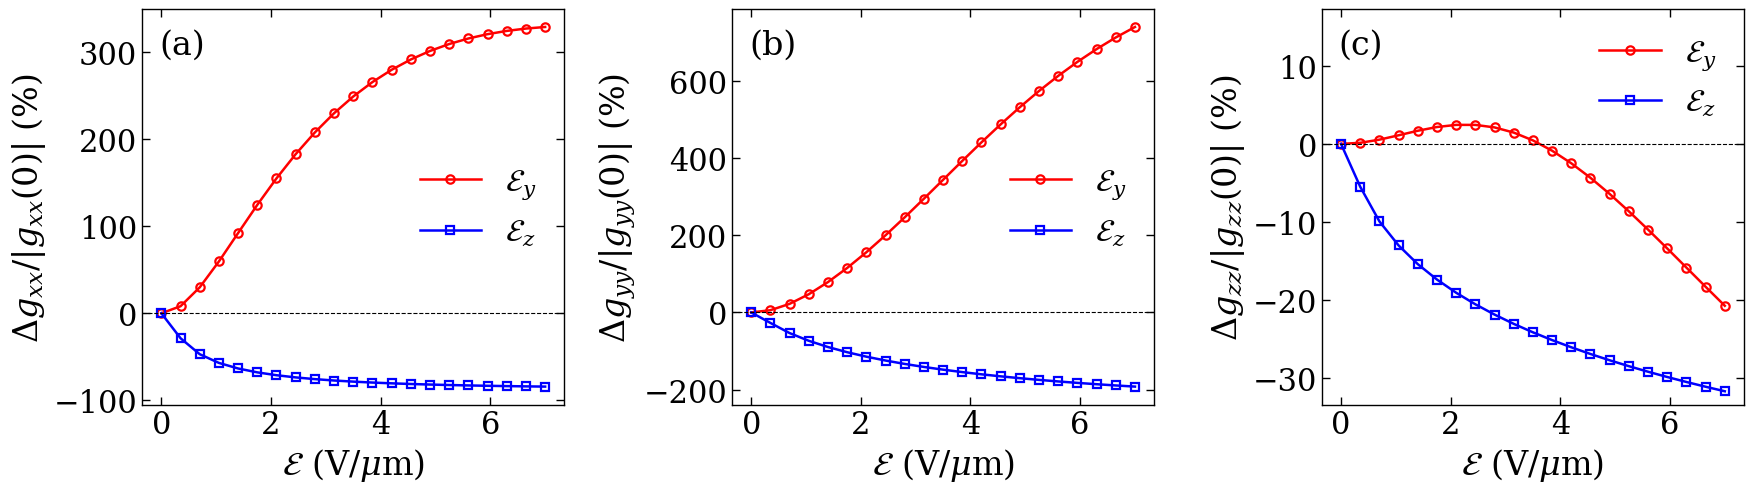

saved gfactor_modulation_N100_L300_dg.pdf / .svg


In [5]:
plot_set("dg", r"$\Delta g_{{{c}}}/|g_{{{c}}}(0)|$ (%)", OUT_PREFIX + "_dg", zero_line=True)